# **Devixo Solutions – AI/ML Internship Program**
## **Task 01:** Python Programming, Data Analysis & Visualization
## **Project:** Laptop Price & Specification Analysis
## **Dataset:** Laptop Dataset


# PART 1 – DATA LOADING & DATA UNDERSTANDING

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> The first part is to load and understand your selected dataset. Make sure it loads successfully before continuing.</div>

## 1.1 Import Required Libraries

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; At minimum, use Pandas, NumPy, Matplotlib and Seaborn.</div>

In [ ]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="ticks", palette="mako_r", font_scale=1.05)
pd.set_option("display.max_columns", 40)

CFG = {"seed": 7, "dpi": 150, "img_dir": "images", "data_dir": "dataset"}
for d in (CFG["img_dir"], CFG["data_dir"]):
    os.makedirs(d, exist_ok=True)

# ---- helper functions used throughout the notebook ----
_fig_no = 0
def save_fig():
    """Tighten layout, save as images/visualization_XX.png and show."""
    global _fig_no
    _fig_no += 1
    plt.tight_layout()
    plt.savefig(f"{CFG['img_dir']}/visualization_{_fig_no:02d}.png", dpi=CFG["dpi"], bbox_inches="tight")
    plt.show()

clean_log = []   # every cleaning step is recorded here
def log_step(step, before, after, note):
    clean_log.append({"Step": step, "Rows Before": before, "Rows After": after,
                      "Rows Removed": before - after, "Note": note})

print("Setup complete")

# ---- notebook UI helpers: styled tables and KPI cards ----
from IPython.display import HTML, display

def pretty(df, gradient=False, fmt="{:,.2f}", vmin=None, vmax=None):
    """Return a nicely styled version of a DataFrame (blue header, zebra rows)."""
    sty = df.style
    fm = {c: "{:,}" for c in df.select_dtypes("integer").columns}
    fm.update({c: fmt for c in df.select_dtypes("float").columns})
    if "count" in df.columns: fm["count"] = "{:,.0f}"
    if fm: sty = sty.format(fm)
    if gradient: sty = sty.background_gradient(cmap="RdBu_r", vmin=vmin, vmax=vmax)
    return (sty.set_table_styles([
        {"selector": "th", "props": [("background-color", "#1f4e79"), ("color", "white"), ("font-weight", "600"), ("padding", "7px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "6px 12px"), ("border-bottom", "1px solid #e1e8ef")]},
        {"selector": "tr:nth-child(even) td", "props": [("background-color", "#f6f9fc")]},
    ]).set_properties(**{"white-space": "normal"}))

def kpi_cards(items):
    """Show a row of coloured KPI cards: items = [(label, value, colour), ...]"""
    cards = "".join(
        f'<div style="flex:1;min-width:105px;background:{c};color:white;border-radius:12px;padding:12px 10px;margin:4px;text-align:center;font-family:sans-serif">'
        f'<div style="font-size:24px;font-weight:700">{v}</div><div style="font-size:12px;opacity:.92">{k}</div></div>' for k, v, c in items)
    display(HTML(f'<div style="display:flex;flex-wrap:wrap">{cards}</div>'))


Setup complete


## 1.2 Load the Dataset

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Load your selected dataset into a Pandas DataFrame using the appropriate Pandas method for CSV.</div>

In [ ]:
URL = "https://raw.githubusercontent.com/AAdewunmi/laptop_prices_prediction_project/main/sample_data/laptop_data.csv"

def load_data(url):
    try:
        return pd.read_csv(url)
    except Exception as e:
        print("Download failed:", e, "\nUpload laptop_data.csv from Kaggle")
        from google.colab import files
        up = files.upload()
        return pd.read_csv(list(up.keys())[0])

raw = load_data(URL)
raw.to_csv(f"{CFG['data_dir']}/laptop_data.csv", index=False)
print("Dataset loaded successfully:", raw.shape)

Dataset loaded successfully: (1303, 12)


## 1.3 Display Dataset Records

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Display the first 5 records, last 5 records, and a random sample of records.</div>

In [ ]:
print("First 5 records");  display(raw.head())
print("Last 5 records");   display(raw.tail())
print("Random sample");    display(raw.sample(5, random_state=CFG["seed"]))

First 5 records


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


Last 5 records


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1298,1298,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64
1299,1299,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.72
1300,1300,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.12
1301,1301,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.92
1302,1302,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32


Random sample


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
347,347,Dell,Ultrabook,15.6,Full HD 1920x1080,Intel Core i7 8650U 1.9GHz,16GB,512GB SSD + 256GB SSD,Intel UHD Graphics 620,Windows 10,1.88kg,85672.1088
1061,1061,Asus,Gaming,17.3,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,16GB,1TB HDD,Nvidia GeForce GTX 965M,No OS,4kg,53173.4400
374,374,Dell,2 in 1 Convertible,13.3,Full HD / Touchscreen 1920x1080,Intel Core i7 8550U 1.8GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows 10,1.62kg,46300.8528
361,361,Asus,Notebook,14.0,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,2kg,50349.6000
1010,1010,Dell,Gaming,15.6,Full HD 1920x1080,Intel Core i5 7300HQ 2.5GHz,8GB,1.0TB Hybrid,Nvidia GeForce GTX 1050,Windows 10,2.65kg,50562.7200


## 1.4 Dataset Information

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Analyse the structure: rows, columns, column names, data types, non-null values and missing values.</div>

In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   TypeName          1303 non-null   object 
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   object 
 5   Cpu               1303 non-null   object 
 6   Ram               1303 non-null   object 
 7   Memory            1303 non-null   object 
 8   Gpu               1303 non-null   object 
 9   OpSys             1303 non-null   object 
 10  Weight            1303 non-null   object 
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), object(9)
memory usage: 122.3+ KB


In [ ]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notnull().sum(),
    "missing": raw.isnull().sum(),
    "unique_values": raw.nunique(),
})
display(overview)

,dtype,non_null,missing,unique_values
Unnamed: 0,int64,1303,0,1303
Company,object,1303,0,19
TypeName,object,1303,0,6
Inches,float64,1303,0,18
ScreenResolution,object,1303,0,40
Cpu,object,1303,0,118
Ram,object,1303,0,9
Memory,object,1303,0,39
Gpu,object,1303,0,110
OpSys,object,1303,0,9


## 1.5 Check Dataset Shape

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Display the shape and clearly identify the number of rows and columns.</div>

In [ ]:
n_rows, n_cols = raw.shape
print(f"Number of Rows    : {n_rows:,}")
print(f"Number of Columns : {n_cols}")

Number of Rows    : 1,303
Number of Columns : 12


In [ ]:
#@title Dataset summary { display-mode: "form" }
kpi_cards([("Rows", f"{raw.shape[0]:,}", "#1f4e79"), ("Columns", raw.shape[1], "#2e75b6"), ("Missing values", f"{int(raw.isnull().sum().sum()):,}", "#27ae60"), ("Duplicate rows", f"{int(raw.duplicated().sum()):,}", "#e67e22")])

## 1.6 Identify Column Types

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Classify columns as numerical, categorical, and date/time (if available), and explain why these types matter.</div>

Numerical columns support averages, correlation and histograms; categorical columns support counts and group comparisons. This dataset has **no date/time column**, so the line chart later uses an ordered numeric variable (RAM size) on the x-axis instead of time.

Important: several columns that look numeric (**Ram** = "8GB", **Weight** = "1.37kg") are stored as **text** with units attached, which is the main data-type problem to fix in Part 2.

In [ ]:
numerical_cols   = raw.select_dtypes(include=np.number).columns.tolist()
categorical_cols = raw.select_dtypes(exclude=np.number).columns.tolist()
date_cols        = []   # none in this dataset

for label, cols in [("Numerical", numerical_cols), ("Categorical (text)", categorical_cols), ("Date/Time", date_cols)]:
    print(f"{label} columns ({len(cols)}): {cols}\n")

Numerical columns (3): ['Unnamed: 0', 'Inches', 'Price']

Categorical (text) columns (9): ['Company', 'TypeName', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight']

Date/Time columns (0): []



## 1.7 Feature Description
| Column | Meaning |
|---|---|
| Unnamed: 0 | Leftover row index from the original export (not a feature) |
| Company | Laptop brand (Dell, HP, Apple, ...) |
| TypeName | Laptop type: Notebook, Gaming, Ultrabook, 2 in 1 Convertible, Workstation, Netbook |
| Inches | Screen size in inches |
| ScreenResolution | Resolution text, may include panel type (IPS) and Touchscreen |
| Cpu | Processor name and clock speed |
| Ram | Memory size, stored as text (e.g. "8GB") |
| Memory | Storage description (e.g. "128GB SSD + 1TB HDD") |
| Gpu | Graphics card |
| OpSys | Operating system |
| Weight | Weight stored as text (e.g. "1.37kg") |
| Price | Laptop price (target variable of interest) |

# PART 2 – DATA CLEANING & PREPROCESSING

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> Real-world datasets often contain missing values, duplicate records, incorrect data types and inconsistent information. Clean the dataset before detailed analysis, and never remove data without explanation.</div>

Every cleaning step below is written into a **cleaning log** so the effect of each decision is visible.

## 2.1 Check Missing Values

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Identify the columns containing missing values, the number of missing values, and their percentage.</div>

Besides real **NaN** values, hidden placeholders such as **?**, empty text or **Unknown** are also checked.

In [ ]:
miss = (raw.isnull().sum().to_frame("Missing Count")
          .assign(**{"Missing %": lambda t: (t["Missing Count"] / len(raw) * 100).round(3)}))
display(pretty(miss.T, fmt="{:,.3f}"))

placeholders = ["?", "", " ", "NA", "N/A", "Unknown", "None", "-"]
print("Hidden placeholder values found:", int(raw.astype(str).isin(placeholders).sum().sum()))
print("Total missing values:", int(raw.isnull().sum().sum()))

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
Missing Count,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Missing %,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Hidden placeholder values found: 0
Total missing values: 0


## 2.2 Handle Missing Values

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Handle missing values with an appropriate method (mean, median, mode, fill, remove rows/columns) and explain why.</div>

**No missing values were found** (including hidden placeholders), so no filling or row removal is needed, and none is applied: inventing values where none are missing would only damage the data.

The one structural issue in this step is the **Unnamed: 0 column**. It is not missing data; it is a leftover row index (0, 1, 2 ...) that carries no information about laptops and would also hide duplicate rows (each duplicate would still look different because of its index). **Method: remove the column.**

In [ ]:
def drop_index_column(df):
    return df.drop(columns=["Unnamed: 0"])

df = drop_index_column(raw)
log_step("2.2 Remove leftover index column", len(raw), len(df), "Column removed, no rows removed")
print("Shape:", df.shape, "| Missing values remaining:", df.isnull().sum().sum())

Shape: (1303, 11) | Missing values remaining: 0


## 2.3 Check Duplicate Records

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Count duplicate records, remove unnecessary duplicates, and verify they have been removed.</div>

In [ ]:
dups = df.duplicated().sum()
print(f"Duplicate rows: {dups} ({dups / len(df) * 100:.2f}%)")
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))

Duplicate rows: 29 (2.23%)


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1263,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.92
1277,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.92
1291,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.92
1172,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32
1274,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32
1288,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32


These rows are identical in **every** column (same brand, specs and price), so they are repeated records of the same listing and would give some laptops extra weight in every average. **Method: keep the first copy and remove the rest.**

In [ ]:
def drop_duplicates(df):
    before = len(df)
    out = df.drop_duplicates().reset_index(drop=True)
    log_step("2.3 Remove duplicate rows", before, len(out), "Identical in all columns")
    return out

df = drop_duplicates(df)
print("Duplicates remaining:", df.duplicated().sum(), "| Rows:", len(df))

Duplicates remaining: 0 | Rows: 1274


## 2.4 Check Data Types

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Inspect all column data types; look for numbers stored as text, dates stored as strings, and categories stored incorrectly.</div>

In [ ]:
print(df.dtypes)
display(df[["Ram", "Weight", "Memory", "ScreenResolution", "Cpu"]].head(5))

Company              object
TypeName             object
Inches              float64
ScreenResolution     object
Cpu                  object
Ram                  object
Memory               object
Gpu                  object
OpSys                object
Weight               object
Price               float64
dtype: object


,Ram,Weight,Memory,ScreenResolution,Cpu
0,8GB,1.37kg,128GB SSD,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz
1,8GB,1.34kg,128GB Flash Storage,1440x900,Intel Core i5 1.8GHz
2,8GB,1.86kg,256GB SSD,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz
3,16GB,1.83kg,512GB SSD,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz
4,8GB,1.37kg,256GB SSD,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz


Issues found – almost every useful column is text:
- **Ram** ("8GB") and **Weight** ("1.37kg") → **numbers stored as text** → units removed, converted to **int** / **float**
- **Memory** ("128GB SSD + 1TB HDD") → parsed into **total storage in GB** and a **storage type**
- **ScreenResolution** ("IPS Panel Full HD 1920x1080") → split into **width**, **height**, **touchscreen** flag, **IPS** flag, and pixel density (**PPI**)
- **Cpu** → **clock speed in GHz** and a **CPU family** (Core i3 / i5 / i7, Celeron, ...)
- **Gpu** → **GPU brand** (Intel / Nvidia / AMD)
- **OpSys** has **macOS** and **Mac OS X** for the same thing → merged into **macOS**
- Text columns with few repeated values → converted to **category**







In [ ]:
def parse_storage(memory):
    """'128GB SSD +  1TB HDD' -> (1128.0, 'HDD + SSD')"""
    total, kinds = 0.0, set()
    for part in memory.split("+"):
        m = re.match(r"\s*([\d.]+)\s*(GB|TB)\s*(.+)", part)
        total += float(m.group(1)) * (1000 if m.group(2) == "TB" else 1)
        kinds.add(m.group(3).replace("Storage", "").strip())
    return total, " + ".join(sorted(kinds))

def cpu_family(cpu):
    for key in ["Core i3", "Core i5", "Core i7", "Core M", "Celeron", "Pentium", "Atom", "Xeon"]:
        if key in cpu:
            return "Intel " + key
    return "AMD" if cpu.startswith("AMD") else "Intel Other"

def fix_types(df):
    res = df["ScreenResolution"].str.extract(r"(\d{3,4})x(\d{3,4})").astype(int)
    storage = df["Memory"].apply(lambda m: pd.Series(parse_storage(m), index=["total_storage_gb", "storage_type"]))
    out = (df.join(storage)
             .assign(ram_gb=df["Ram"].str.replace("GB", "").astype(int),
                     weight_kg=df["Weight"].str.replace("kg", "").astype(float),
                     res_width=res[0], res_height=res[1],
                     touchscreen=df["ScreenResolution"].str.contains("Touchscreen").astype(int),
                     ips_panel=df["ScreenResolution"].str.contains("IPS").astype(int),
                     cpu_ghz=df["Cpu"].str.extract(r"([\d.]+)GHz")[0].astype(float),
                     cpu_family=df["Cpu"].apply(cpu_family),
                     gpu_brand=df["Gpu"].str.split().str[0],
                     OpSys=df["OpSys"].replace({"Mac OS X": "macOS"})))
    out["ppi"] = (np.sqrt(out["res_width"] ** 2 + out["res_height"] ** 2) / out["Inches"]).round(1)
    # merge very rare storage combinations (fewer than 10 laptops) into 'Other'
    rare = out["storage_type"].value_counts()[lambda s: s < 10].index
    out["storage_type"] = out["storage_type"].replace({r: "Other" for r in rare})
    out = out.drop(columns=["Ram", "Weight", "Memory", "ScreenResolution"])
    for c in ["Company", "TypeName", "OpSys", "cpu_family", "gpu_brand", "storage_type"]:
        out[c] = out[c].astype("category")
    return out

df = fix_types(df)
print(df.dtypes)
display(df.head())

Company             category
TypeName            category
Inches               float64
Cpu                   object
Gpu                   object
OpSys               category
Price                float64
total_storage_gb     float64
storage_type        category
ram_gb                 int64
weight_kg            float64
res_width              int64
res_height             int64
touchscreen            int64
ips_panel              int64
cpu_ghz              float64
cpu_family          category
gpu_brand           category
ppi                  float64
dtype: object


,Company,TypeName,Inches,Cpu,Gpu,OpSys,Price,total_storage_gb,storage_type,ram_gb,weight_kg,res_width,res_height,touchscreen,ips_panel,cpu_ghz,cpu_family,gpu_brand,ppi
0,Apple,Ultrabook,13.3,Intel Core i5 2.3GHz,Intel Iris Plus Graphics 640,macOS,71378.6832,128.0,SSD,8,1.37,2560,1600,0,1,2.3,Intel Core i5,Intel,227.0
1,Apple,Ultrabook,13.3,Intel Core i5 1.8GHz,Intel HD Graphics 6000,macOS,47895.5232,128.0,Flash,8,1.34,1440,900,0,0,1.8,Intel Core i5,Intel,127.7
2,HP,Notebook,15.6,Intel Core i5 7200U 2.5GHz,Intel HD Graphics 620,No OS,30636.0000,256.0,SSD,8,1.86,1920,1080,0,0,2.5,Intel Core i5,Intel,141.2
3,Apple,Ultrabook,15.4,Intel Core i7 2.7GHz,AMD Radeon Pro 455,macOS,135195.3360,512.0,SSD,16,1.83,2880,1800,0,1,2.7,Intel Core i7,AMD,220.5
4,Apple,Ultrabook,13.3,Intel Core i5 3.1GHz,Intel Iris Plus Graphics 650,macOS,96095.8080,256.0,SSD,8,1.37,2560,1600,0,1,3.1,Intel Core i5,Intel,227.0


## 2.5 Rename Columns

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; If column names are unclear, rename them so they are clear, meaningful, consistent and easy to understand.</div>

In [ ]:
df = df.rename(columns={
    "Company": "brand", "TypeName": "laptop_type", "Inches": "screen_inches",
    "OpSys": "os", "Price": "price", "Cpu": "cpu", "Gpu": "gpu",
})
print(list(df.columns))

['brand', 'laptop_type', 'screen_inches', 'cpu', 'gpu', 'os', 'price', 'total_storage_gb', 'storage_type', 'ram_gb', 'weight_kg', 'res_width', 'res_height', 'touchscreen', 'ips_panel', 'cpu_ghz', 'cpu_family', 'gpu_brand', 'ppi']


## 2.6 Check Invalid Values

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Identify values that do not make logical sense (negative values, unrealistic values, invalid categories, impossible dates) and explain how they were handled.</div>

In [ ]:
checks = pd.Series({
    "price <= 0": (df["price"] <= 0).sum(),
    "ram_gb <= 0": (df["ram_gb"] <= 0).sum(),
    "weight_kg <= 0 or > 6 kg": ((df["weight_kg"] <= 0) | (df["weight_kg"] > 6)).sum(),
    "screen_inches outside 10-19": (~df["screen_inches"].between(10, 19)).sum(),
    "total_storage_gb <= 0": (df["total_storage_gb"] <= 0).sum(),
    "resolution width/height not positive": ((df["res_width"] <= 0) | (df["res_height"] <= 0)).sum(),
    "cpu_ghz outside 0.5-5": (~df["cpu_ghz"].between(0.5, 5)).sum(),
    "invalid ppi (<=0)": (df["ppi"] <= 0).sum(),
})
display(checks.to_frame("Rows"))

q1, q3 = df["price"].quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
print(f"\nPrice outliers by the IQR rule (price > {fence:,.0f}): {(df['price'] > fence).sum()}")
display(df[df["price"] > fence][["brand", "laptop_type", "ram_gb", "cpu_family", "price"]].sort_values("price", ascending=False).head(5))

,Rows
price <= 0,0
ram_gb <= 0,0
weight_kg <= 0 or > 6 kg,0
screen_inches outside 10-19,0
total_storage_gb <= 0,0
resolution width/height not positive,0
cpu_ghz outside 0.5-5,0
invalid ppi (<=0),0



Price outliers by the IQR rule (price > 150,690): 28


,brand,laptop_type,ram_gb,cpu_family,price
196,Razer,Gaming,32,Intel Core i7,324954.72
830,Razer,Gaming,32,Intel Core i7,292986.72
610,Lenovo,Notebook,32,Intel Xeon,261018.72
749,HP,Workstation,16,Intel Xeon,233845.92
1066,Asus,Gaming,64,Intel Core i7,211788.00


**How they were handled**
- No negative, zero or unrealistic values were found in any column, so **no rows are removed** in this step.
- The high-priced laptops flagged by the IQR rule are **real** premium models (gaming laptops, workstations with 32 GB+ RAM), not errors, so they are **kept** and discussed in the analysis. Removing them would hide the top of the market.

In [ ]:
log_step("2.6 Remove invalid values", len(df), len(df), "None found; price outliers are genuine and kept")
display(pretty(pd.DataFrame(clean_log)))

,Step,Rows Before,Rows After,Rows Removed,Note
0,2.2 Remove leftover index column,"1,303","1,303",0,"Column removed, no rows removed"
1,2.3 Remove duplicate rows,"1,303","1,274",29,Identical in all columns
2,2.6 Remove invalid values,"1,274","1,274",0,None found; price outliers are genuine and kept


## 2.7 Verify the Cleaned Dataset

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Verify missing values, duplicates, data types, shape and basic statistics, and show evidence in the notebook.</div>

In [ ]:
#@title Cleaned dataset summary { display-mode: "form" }
kpi_cards([("Raw rows", f"{len(raw):,}", "#6c757d"), ("Clean rows", f"{len(df):,}", "#1f4e79"), ("Columns", df.shape[1], "#2e75b6"), ("Missing values", int(df.isnull().sum().sum()), "#27ae60"), ("Duplicates", int(df.duplicated().sum()), "#27ae60")])


In [ ]:
verification = {
    "Missing values": int(df.isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Shape (rows, cols)": df.shape,
    "Raw rows": len(raw),
    "Rows kept": f"{len(df) / len(raw) * 100:.1f}%",
}
for k, v in verification.items():
    print(f"{k:20s}: {v}")
print()
display(pretty(df.dtypes.astype(str).value_counts().to_frame("columns")))
display(pretty(df.describe().T.round(2)))
df.to_csv(f"{CFG['data_dir']}/laptop_data_cleaned.csv", index=False)

Missing values      : 0
Duplicate rows      : 0
Shape (rows, cols)  : (1274, 19)
Raw rows            : 1303
Rows kept           : 97.8%



,columns
category,6
float64,6
int64,5
object,2


,count,mean,std,min,25%,50%,75%,max
screen_inches,"1,274",15.02,1.43,10.10,14.00,15.60,15.60,18.40
price,"1,274","60,503.19","37,333.22","9,270.72","32,495.61","52,693.92","79,773.48","324,954.72"
total_storage_gb,"1,274",611.47,469.97,8.00,256.00,500.00,"1,000.00","2,512.00"
ram_gb,"1,274",8.44,5.10,2.00,4.00,8.00,8.00,64.00
weight_kg,"1,274",2.04,0.67,0.69,1.50,2.04,2.31,4.70
res_width,"1,274","1,900.46",493.31,"1,366.00","1,920.00","1,920.00","1,920.00","3,840.00"
res_height,"1,274","1,074.14",283.87,768.00,"1,080.00","1,080.00","1,080.00","2,160.00"
touchscreen,"1,274",0.15,0.35,0.00,0.00,0.00,0.00,1.00
ips_panel,"1,274",0.28,0.45,0.00,0.00,0.00,1.00,1.00
cpu_ghz,"1,274",2.30,0.50,0.90,2.00,2.50,2.70,3.60


# PART 3 – EXPLORATORY DATA ANALYSIS (EDA)

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> Your EDA should answer: What information does the dataset contain? Which variables are important? Which categories are most frequent? What are the highest and lowest values? Are there outliers? Which variables are related?</div>

## 3.1 Descriptive Statistics

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Calculate and analyse mean, median, mode, minimum, maximum, range, standard deviation and variance; explain results in simple language.</div>

In [ ]:
num_cols = ["price", "screen_inches", "ram_gb", "weight_kg", "total_storage_gb", "cpu_ghz", "ppi"]

def summarise(frame, cols):
    s = frame[cols]
    return pd.DataFrame({
        "Mean": s.mean(), "Median": s.median(), "Mode": s.mode().iloc[0],
        "Min": s.min(), "Max": s.max(), "Range": s.max() - s.min(),
        "Std Dev": s.std(), "Variance": s.var(),
    }).round(2)

stats = summarise(df, num_cols)
display(pretty(stats))

,Mean,Median,Mode,Min,Max,Range,Std Dev,Variance
price,"60,503.19","52,693.92","58,554.72","9,270.72","324,954.72","315,684.00","37,333.22","1,393,769,537.87"
screen_inches,15.02,15.60,15.60,10.10,18.40,8.30,1.43,2.04
ram_gb,8.44,8.00,8.00,2.00,64.00,62.00,5.10,25.99
weight_kg,2.04,2.04,2.20,0.69,4.70,4.01,0.67,0.45
total_storage_gb,611.47,500.00,256.00,8.00,"2,512.00","2,504.00",469.97,"220,873.66"
cpu_ghz,2.30,2.50,2.50,0.90,3.60,2.70,0.50,0.25
ppi,147.02,141.20,141.20,90.60,352.50,261.90,42.98,"1,847.12"


## 3.2 Mean

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Mean = Σx / n, where Σx is the sum of all values and n the number of observations. Explain what the mean tells you.</div>

In [ ]:
for col in ["price", "ram_gb", "weight_kg", "screen_inches"]:
    manual = df[col].sum() / len(df)
    print(f"{col:14s} manual Σx/n = {manual:12.2f} | pandas mean = {df[col].mean():12.2f}")

price          manual Σx/n =     60503.19 | pandas mean =     60503.19
ram_gb         manual Σx/n =         8.44 | pandas mean =         8.44
weight_kg      manual Σx/n =         2.04 | pandas mean =         2.04
screen_inches  manual Σx/n =        15.02 | pandas mean =        15.02


The average laptop costs about **60,500**, has **8.4 GB of RAM**, weighs **2.04 kg**, and has a **15-inch** screen. This describes the typical mid-range 15-inch laptop that dominates the market.

## 3.3 Median

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; The median is the middle value when ordered; explain why it can be more useful than the mean when outliers are present.</div>

In [ ]:
cmp = pd.DataFrame({"Mean": df[num_cols].mean(), "Median": df[num_cols].median()})
cmp["Mean - Median"] = cmp["Mean"] - cmp["Median"]
display(pretty(cmp.round(2)))
print("Price skewness:", round(df["price"].skew(), 2))

,Mean,Median,Mean - Median
price,"60,503.19","52,693.92","7,809.27"
screen_inches,15.02,15.60,-0.58
ram_gb,8.44,8.00,0.44
weight_kg,2.04,2.04,0.00
total_storage_gb,611.47,500.00,111.47
cpu_ghz,2.30,2.50,-0.20
ppi,147.02,141.20,5.82


Price skewness: 1.51


Price has a **mean (60,503) well above its median (52,694)** and a skewness of 1.5: a small number of very expensive gaming laptops and workstations pull the average upward. The **median is the better description of a typical laptop price**. Screen size shows the opposite: the median (15.6) is above the mean (15.0), because a few small 11–12 inch laptops pull the average down.

## 3.4 Mode

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Identify the most frequently occurring value; mode is especially useful for categorical variables.</div>

In [ ]:
for col in ["brand", "laptop_type", "os", "cpu_family", "gpu_brand", "storage_type"]:
    top = df[col].value_counts()
    print(f"Most common {col:12s}: {top.index[0]}  ({top.iloc[0]:,} laptops, {top.iloc[0] / len(df) * 100:.1f}%)")
print("\nMost common RAM size (GB):", df["ram_gb"].mode()[0])
print("Most common screen size  :", df["screen_inches"].mode()[0], "inches")
print("Most common resolution   :", f"{df['res_width'].mode()[0]} px wide")

Most common brand       : Dell  (291 laptops, 22.8%)
Most common laptop_type : Notebook  (706 laptops, 55.4%)
Most common os          : Windows 10  (1,047 laptops, 82.2%)
Most common cpu_family  : Intel Core i7  (515 laptops, 40.4%)
Most common gpu_brand   : Intel  (703 laptops, 55.2%)
Most common storage_type: SSD  (635 laptops, 49.8%)

Most common RAM size (GB): 8
Most common screen size  : 15.6 inches
Most common resolution   : 1920 px wide


The typical laptop is a **Dell** (Dell, Lenovo and HP together make up about two-thirds of the data), a **Notebook**, running **Windows 10**, with an **Intel Core i7**, **Intel** graphics, **SSD** storage, **8 GB RAM** and a **15.6-inch** screen. Mode is not meaningful for the continuous `price` column.

## 3.5 Standard Deviation

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Calculate the standard deviation; a larger value generally indicates greater variation around the mean.</div>

In [ ]:
variation = pd.DataFrame({"Std Dev": df[num_cols].std(),
                          "Coefficient of Variation %": df[num_cols].std() / df[num_cols].mean() * 100})
display(pretty(variation.sort_values("Coefficient of Variation %", ascending=False).round(2)))

,Std Dev,Coefficient of Variation %
total_storage_gb,469.97,76.86
price,"37,333.22",61.70
ram_gb,5.10,60.38
weight_kg,0.67,32.81
ppi,42.98,29.23
cpu_ghz,0.50,21.86
screen_inches,1.43,9.52


The columns use different units, so the **coefficient of variation** (std ÷ mean) is used to compare them. **Storage size (77%)**, **price (62%)** and **RAM (60%)** vary most, from tiny 16 GB flash drives to multi-terabyte setups, and from budget to premium machines. **Screen size (10%)** varies least: almost every laptop is 13–17 inches.

## 3.6 Correlation Analysis

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; Create a correlation matrix (range −1 to +1) for suitable numerical variables and explain the most important correlations.</div>

In [ ]:
corr_cols = ["price", "ram_gb", "total_storage_gb", "cpu_ghz", "ppi", "screen_inches", "weight_kg", "touchscreen", "ips_panel"]
corr = df[corr_cols].corr().round(2)
display(pretty(corr, gradient=True, vmin=-1, vmax=1))

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().sort_values("r", key=abs, ascending=False))
pairs.columns = ["var_1", "var_2", "r"]
print("Strongest relationships:"); display(pairs.head(6))
print("Correlation with price:"); print(corr["price"].drop("price").sort_values(ascending=False))

,price,ram_gb,total_storage_gb,cpu_ghz,ppi,screen_inches,weight_kg,touchscreen,ips_panel
price,1.00,0.74,0.16,0.43,0.47,0.07,0.21,0.19,0.25
ram_gb,0.74,1.00,0.35,0.37,0.29,0.24,0.39,0.11,0.20
total_storage_gb,0.16,0.35,1.00,0.24,-0.12,0.54,0.55,-0.14,-0.01
cpu_ghz,0.43,0.37,0.24,1.00,0.04,0.31,0.32,-0.09,0.06
ppi,0.47,0.29,-0.12,0.04,1.00,-0.41,-0.32,0.45,0.29
screen_inches,0.07,0.24,0.54,0.31,-0.41,1.00,0.83,-0.36,-0.11
weight_kg,0.21,0.39,0.55,0.32,-0.32,0.83,1.00,-0.29,0.02
touchscreen,0.19,0.11,-0.14,-0.09,0.45,-0.36,-0.29,1.00,0.14
ips_panel,0.25,0.20,-0.01,0.06,0.29,-0.11,0.02,0.14,1.00


Strongest relationships:


,var_1,var_2,r
30,screen_inches,weight_kg,0.83
0,price,ram_gb,0.74
18,total_storage_gb,weight_kg,0.55
17,total_storage_gb,screen_inches,0.54
3,price,ppi,0.47
28,ppi,touchscreen,0.45


Correlation with price:
ram_gb              0.74
ppi                 0.47
cpu_ghz             0.43
ips_panel           0.25
weight_kg           0.21
touchscreen         0.19
total_storage_gb    0.16
screen_inches       0.07
Name: price, dtype: float64


- **ram_gb ↔ price (+0.74):** RAM is by far the strongest single link with price; more RAM, higher price
- **ppi ↔ price (+0.47)** and **cpu_ghz ↔ price (+0.43):** sharper screens and faster processors cost more
- **screen_inches ↔ weight_kg (+0.83):** bigger screens mean heavier laptops
- **screen_inches ↔ price (+0.07):** screen size alone has almost no effect on price

# PART 4 – DATA VISUALIZATION

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> Create at least 10 different visualizations. Each should have a clear title, axis labels, a suitable figure size and readable text, and should communicate a useful finding.</div>

Each chart is saved automatically into **images/** by the **save_fig()** helper.

## Visualization Overview

All 10 required chart types (4.1 – 4.10) are built below, each with its own heading, a clear title, axis labels and a written interpretation.

| No. | Chart type | What it shows | Saved file |
|---|---|---|---|
| 4.1 | **Histogram** | Distribution of Laptop Prices | `images/visualization_01.png` |
| 4.2 | **Bar Chart** | Average Price by Brand | `images/visualization_02.png` |
| 4.3 | **Pie Chart** | Share of Laptops by Type | `images/visualization_03.png` |
| 4.4 | **Scatter Plot** | RAM vs. Price | `images/visualization_04.png` |
| 4.5 | **Line Chart** | Average Price by RAM Size | `images/visualization_05.png` |
| 4.6 | **Box Plot** | Price by Laptop Type | `images/visualization_06.png` |
| 4.7 | **Correlation Heatmap** | Specifications and Price | `images/visualization_07.png` |
| 4.8 | **Count Plot** | Laptops by Storage Type | `images/visualization_08.png` |
| 4.9 | **Pair Plot** | Key Specifications by Laptop Type | `images/visualization_09.png` |
| 4.10 | **Violin Plot** | Price by CPU Family | `images/visualization_10.png` |


In [ ]:
TYPE_ORDER = df.groupby("laptop_type", observed=True)["price"].mean().sort_values(ascending=False).index.tolist()
TYPE_COLORS = dict(zip(TYPE_ORDER, sns.color_palette("viridis", len(TYPE_ORDER))))

## 4.1 Histogram – Distribution of Laptop Prices

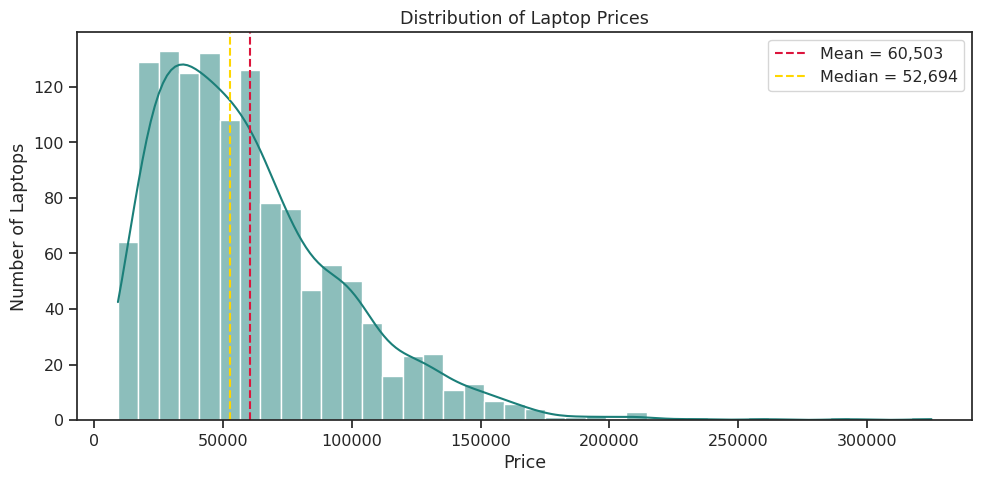

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["price"], bins=40, kde=True, color="#1b7f79", ax=ax)
ax.axvline(df["price"].mean(), color="crimson", ls="--", label=f"Mean = {df['price'].mean():,.0f}")
ax.axvline(df["price"].median(), color="gold", ls="--", label=f"Median = {df['price'].median():,.0f}")
ax.set(title="Distribution of Laptop Prices", xlabel="Price", ylabel="Number of Laptops")
ax.legend(); save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>Prices are strongly right-skewed. Most laptops cost between about 32,000 and 79,000, while a thin tail stretches past 300,000. The mean (60,503) is above the median (52,694) because of those premium machines.</div>

## 4.2 Bar Chart – Average Price by Brand

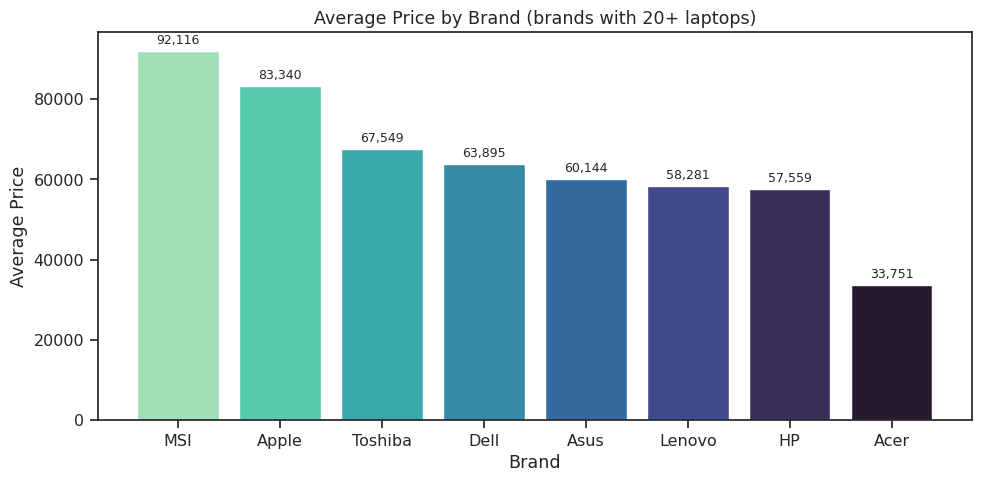

In [ ]:
brand_stats = df.groupby("brand", observed=True)["price"].agg(["mean", "count"]).query("count >= 20").sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(brand_stats.index, brand_stats["mean"], color=sns.color_palette("mako_r", len(brand_stats)))
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in brand_stats["mean"]], padding=3, fontsize=9)
ax.set(title="Average Price by Brand (brands with 20+ laptops)", xlabel="Brand", ylabel="Average Price")
save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>Among brands with at least 20 laptops, <b>MSI (about 92,100)</b> is the most expensive on average, followed by Apple (83,300), and <b>Acer (about 33,800)</b> is the cheapest. Dell, Lenovo and HP, the three biggest sellers, sit in the middle at around 58,000–64,000.</div>

## 4.3 Pie Chart – Share of Laptops by Type

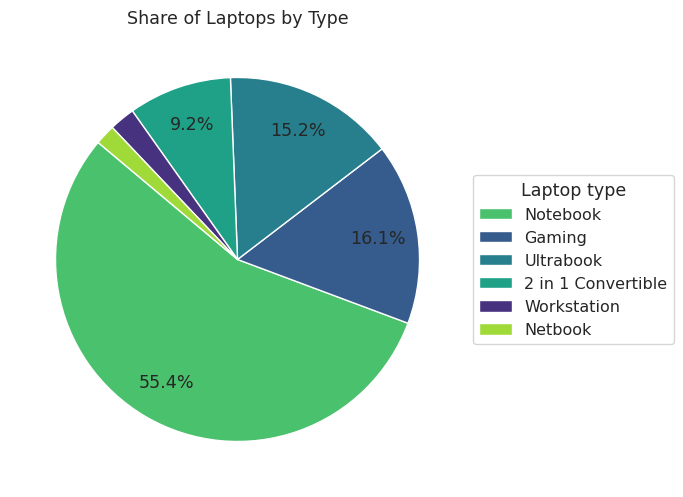

In [ ]:
share = df["laptop_type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(share, labels=None, autopct=lambda p: f"{p:.1f}%" if p > 3 else "", startangle=140, pctdistance=0.78,
       colors=[TYPE_COLORS[t] for t in share.index], wedgeprops={"edgecolor": "white"})
ax.legend(share.index, loc="center left", bbox_to_anchor=(1, 0.5), title="Laptop type")
ax.set_title("Share of Laptops by Type")
save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>More than half of all laptops (<b>55.4%</b>) are standard Notebooks, followed by Gaming (16.1%) and Ultrabook (15.2%). Workstations (2.3%) and Netbooks (1.8%) are niche.</div>

## 4.4 Scatter Plot – RAM vs. Price

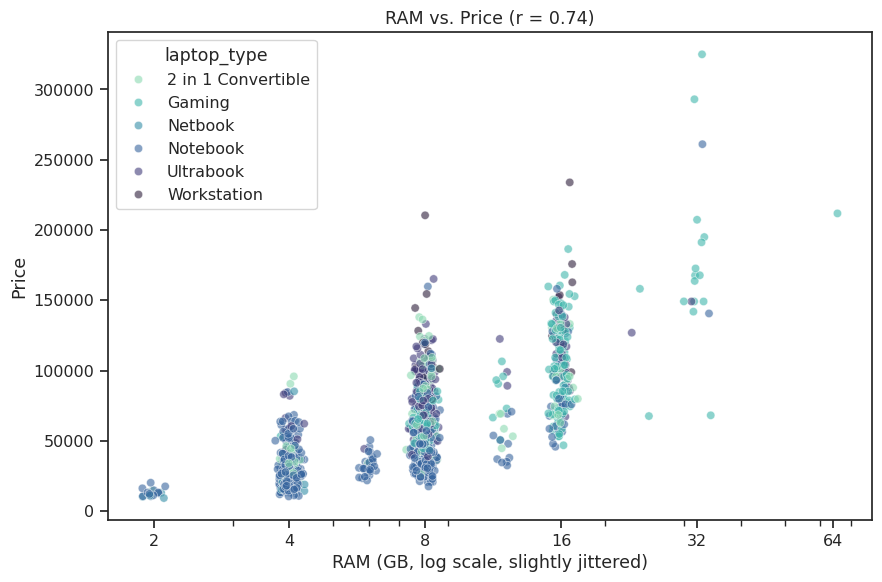

In [ ]:
rng = np.random.default_rng(CFG["seed"])
plot_df = df.assign(ram_jitter=df["ram_gb"] * np.exp(rng.normal(0, 0.03, len(df))))
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="ram_jitter", y="price", hue="laptop_type", alpha=0.6, ax=ax)
ax.set_xscale("log"); ax.set_xticks([2, 4, 8, 16, 32, 64]); ax.set_xticklabels([2, 4, 8, 16, 32, 64])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set(title=f"RAM vs. Price (r = {df['ram_gb'].corr(df['price']):.2f})", xlabel="RAM (GB, log scale, slightly jittered)", ylabel="Price")
save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>There is a clear <b>positive relationship (r = 0.74)</b>. Each step up in RAM moves the price band upward: about 80% of 4 GB laptops cost less than 40,000, while 16 GB+ laptops have a median price of about 104,000 and reach over 300,000. Within one RAM size there is still wide variation, so RAM alone does not decide the price.</div>

## 4.5 Line Chart – Average Price by RAM Size

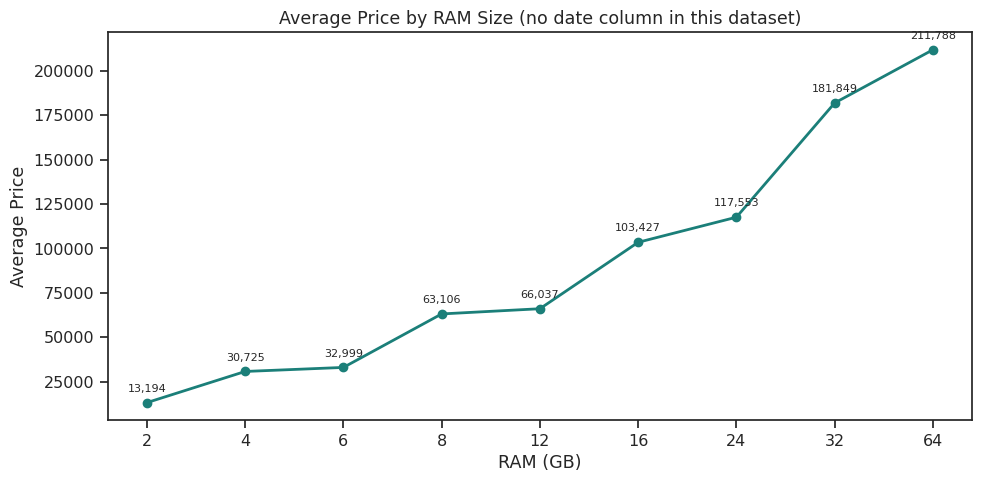

In [ ]:
by_ram = df.groupby("ram_gb")["price"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(by_ram.index.astype(str), by_ram["mean"], marker="o", lw=2, color="#1b7f79")
for x, (m, c) in zip(by_ram.index.astype(str), by_ram.values):
    ax.annotate(f"{m:,.0f}", (x, m), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set(title="Average Price by RAM Size (no date column in this dataset)", xlabel="RAM (GB)", ylabel="Average Price")
save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>The average price climbs steadily with RAM: about <b>13,200 for 2 GB</b>, 30,700 for 4 GB, <b>63,100 for 8 GB</b>, 103,400 for 16 GB and <b>181,800 for 32 GB</b>. The biggest jumps are from 16→32 GB (about +78,000) and 8→16 GB (about +40,000). The dataset has no dates, so RAM is used as the ordered x-axis for this line chart.</div>

## 4.6 Box Plot – Price by Laptop Type

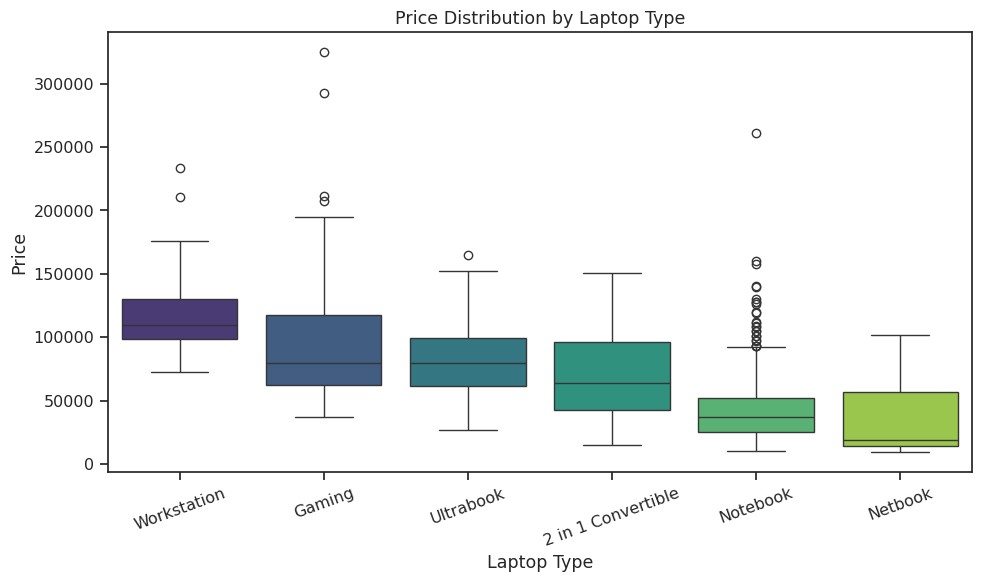

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="laptop_type", y="price", order=TYPE_ORDER, palette=TYPE_COLORS, ax=ax)
ax.set(title="Price Distribution by Laptop Type", xlabel="Laptop Type", ylabel="Price")
ax.tick_params(axis="x", rotation=20); save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br><b>Workstations</b> have the highest median price (about 110,000), then Gaming (about 79,500) and Ultrabook (about 79,900). <b>Notebooks</b> (median about 37,000) and <b>Netbooks</b> (about 18,900) are the budget end. Gaming and Workstation boxes are tall, so prices vary a lot within those types, and 23 of the 28 high-price outliers belong to them.</div>

## 4.7 Correlation Heatmap – Specifications and Price

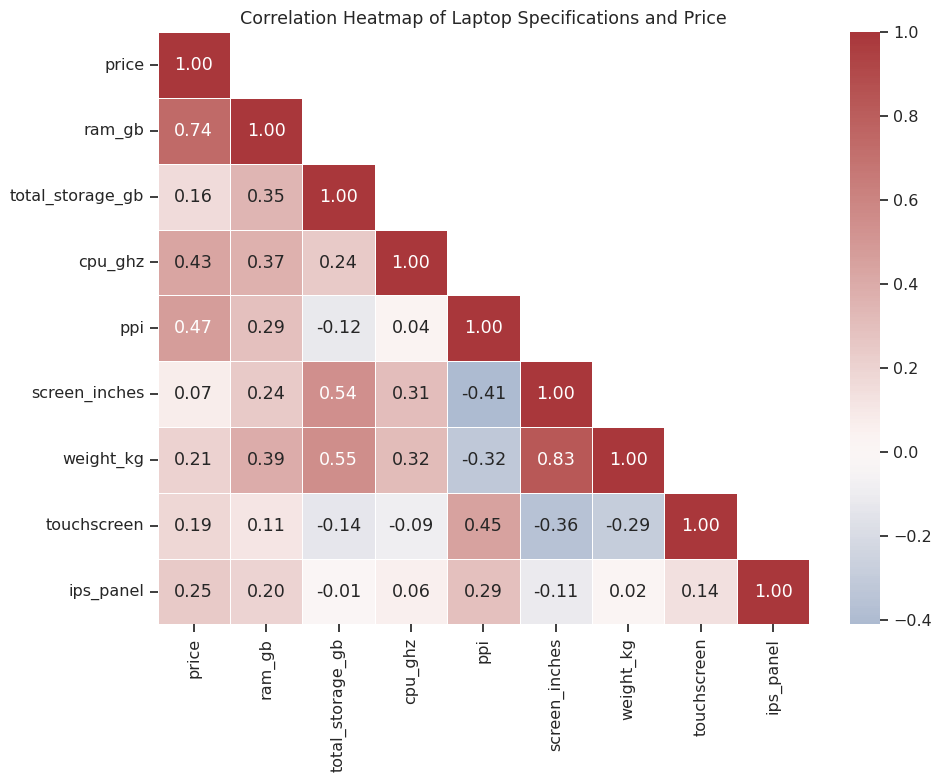

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Laptop Specifications and Price")
save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>The price row is dominated by <b>RAM (+0.74)</b>, with moderate links to PPI (+0.47) and CPU speed (+0.43). Weight and screen size are strongly linked to each other (+0.83) but not to price. Touchscreen and IPS have small positive links.</div>

## 4.8 Count Plot – Laptops by Storage Type

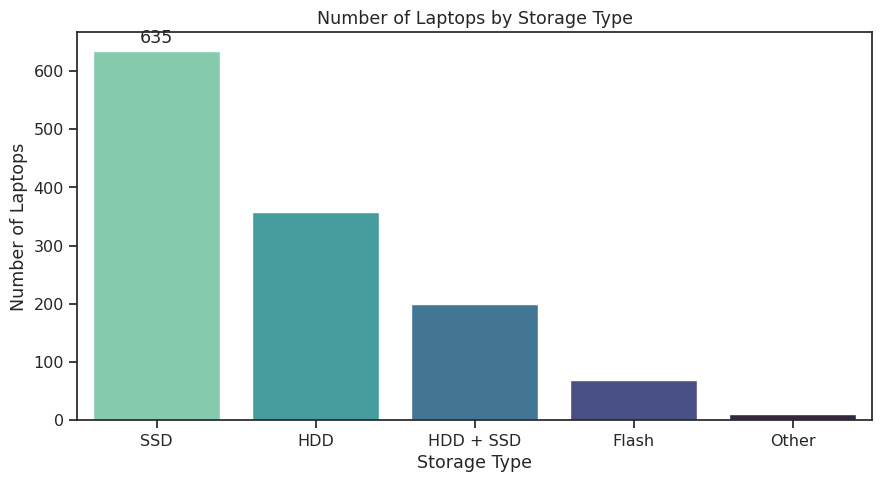

In [ ]:
order = df["storage_type"].value_counts().index
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=df, x="storage_type", order=order, palette="mako_r", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Number of Laptops by Storage Type", xlabel="Storage Type", ylabel="Number of Laptops")
save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br><b>SSD-only</b> laptops are the most common (about 50%), followed by HDD-only (28%) and HDD + SSD combinations (16%). Flash storage (5%) is the cheapest on average (about 27,900). SSD laptops average about <b>70,200</b> versus <b>35,100</b> for HDD-only, a price gap of roughly 2x.</div>

## 4.9 Pair Plot – Key Specifications by Laptop Type

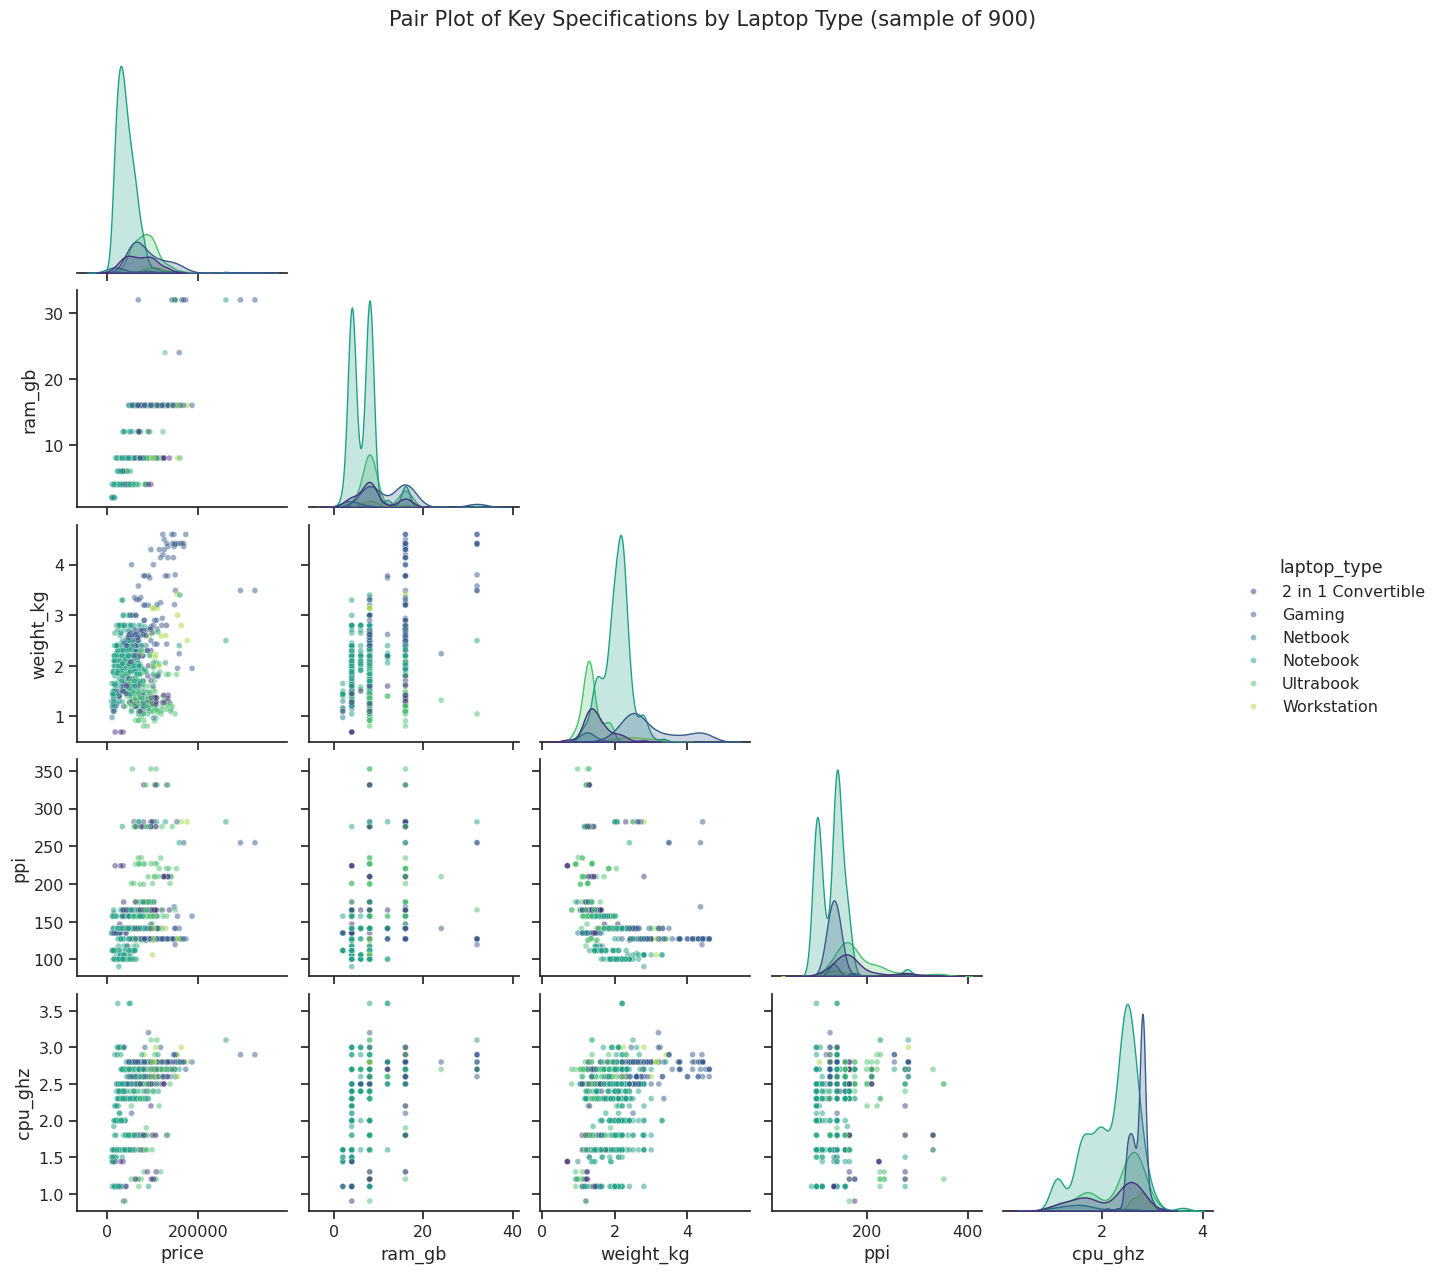

In [ ]:
cols = ["price", "ram_gb", "weight_kg", "ppi", "cpu_ghz"]
ps = df[cols + ["laptop_type"]].sample(900, random_state=CFG["seed"])
g = sns.pairplot(ps, hue="laptop_type", corner=True, palette="viridis", plot_kws={"alpha": 0.5, "s": 18})
g.fig.suptitle("Pair Plot of Key Specifications by Laptop Type (sample of 900)", y=1.02)
_fig_no += 1
g.savefig(f"{CFG['img_dir']}/visualization_{_fig_no:02d}.png", dpi=CFG["dpi"], bbox_inches="tight")
plt.show()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>The pair plot shows every pairwise relationship at once. Price rises with RAM, PPI and CPU speed, and laptop types form visible clusters: Ultrabooks are light, while Gaming and Workstation machines are heavy with high RAM and price.</div>

## 4.10 Violin Plot – Price by CPU Family

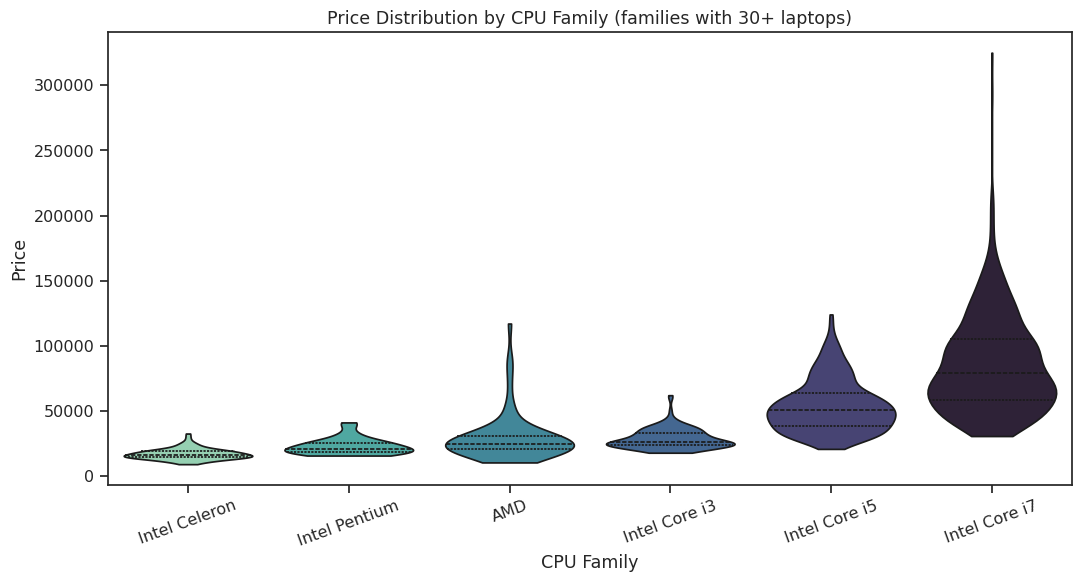

In [ ]:
fam = df["cpu_family"].value_counts()
main_fams = fam[fam >= 30].index
order = df[df["cpu_family"].isin(main_fams)].groupby("cpu_family", observed=True)["price"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 6))
sns.violinplot(data=df[df["cpu_family"].isin(main_fams)], x="cpu_family", y="price", order=order, palette="mako_r", cut=0, inner="quartile", ax=ax)
ax.set(title="Price Distribution by CPU Family (families with 30+ laptops)", xlabel="CPU Family", ylabel="Price")
ax.tick_params(axis="x", rotation=20); save_fig()

<div style="background:#e9f7ef;border-left:6px solid #27ae60;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">💡&nbsp; <b>Interpretation</b><br>The processor family orders the price distributions clearly. <b>Core i7</b> laptops average about <b>85,900</b>, Core i5 about <b>54,100</b>, and Core i3 about <b>28,900</b>. Celeron and AMD laptops cluster at the low end (about 17,100 and 29,900). The i7 violin spans a very wide price range, because i7 appears in everything from ultrabooks to gaming machines.</div>

# PART 5 – DATA INSIGHTS & FINDINGS

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> Write at least 10 meaningful insights based on your actual dataset: highest/lowest category, most common category, averages, extremes, trends, correlations, outliers and unexpected findings.</div>

All numbers are computed live from the cleaned data and collected into a table.

In [ ]:
b = df.groupby("brand", observed=True)["price"].agg(["mean", "count"]).query("count >= 20")["mean"]
t = df.groupby("laptop_type", observed=True)["price"].mean()
by_ram = df.groupby("ram_gb")["price"].mean()
cpu = df.groupby("cpu_family", observed=True)["price"].agg(["mean", "count"]).query("count >= 30")["mean"]
gpu = df.groupby("gpu_brand", observed=True)["price"].mean()
st = df.groupby("storage_type", observed=True)["price"].mean()
cv = (df[num_cols].std() / df[num_cols].mean()).sort_values(ascending=False)
cp = corr["price"].drop("price")
wt = df.groupby("laptop_type", observed=True)["weight_kg"].mean()
q1, q3 = df["price"].quantile([.25, .75]); n_out = int((df["price"] > q3 + 1.5 * (q3 - q1)).sum())
os_share = df["os"].value_counts(normalize=True) * 100

insights = [
 ("Highest-priced brand (20+ laptops)", f"{b.idxmax()} - average {b.max():,.0f}"),
 ("Lowest-priced brand (20+ laptops)",  f"{b.idxmin()} - average {b.min():,.0f}"),
 ("Most common brand",                  f"{df['brand'].value_counts().index[0]} ({df['brand'].value_counts().iloc[0]} laptops); top 3 brands = {df['brand'].value_counts().head(3).sum() / len(df) * 100:.0f}% of the market"),
 ("Most common laptop type",            f"{df['laptop_type'].value_counts().index[0]} ({df['laptop_type'].value_counts(normalize=True).iloc[0] * 100:.1f}%)"),
 ("Most / least expensive type",        f"{t.idxmax()} ({t.max():,.0f}) / {t.idxmin()} ({t.min():,.0f})"),
 ("Average and median price",           f"mean {df['price'].mean():,.0f} vs median {df['price'].median():,.0f}; max {df['price'].max():,.0f}, min {df['price'].min():,.0f}"),
 ("Strongest price driver",             f"{cp.idxmax()} (r = {cp.max():+.2f}); weakest: {cp.abs().idxmin()} (r = {cp[cp.abs().idxmin()]:+.2f})"),
 ("RAM effect",                         f"average price rises from {by_ram[4]:,.0f} (4 GB) to {by_ram[8]:,.0f} (8 GB) to {by_ram[16]:,.0f} (16 GB)"),
 ("Processor effect",                   f"Core i7 averages {cpu['Intel Core i7']:,.0f} vs Core i5 {cpu['Intel Core i5']:,.0f} vs Core i3 {cpu['Intel Core i3']:,.0f}"),
 ("Graphics effect",                    f"Nvidia-GPU laptops average {gpu['Nvidia']:,.0f} vs Intel {gpu['Intel']:,.0f} and AMD {gpu['AMD']:,.0f}"),
 ("SSD vs HDD",                         f"SSD-only laptops average {st['SSD']:,.0f}, HDD-only {st['HDD']:,.0f} ({st['SSD'] / st['HDD']:.1f}x)"),
 ("Touchscreen / IPS premium",          f"touchscreen +{df.groupby('touchscreen')['price'].mean()[1] / df.groupby('touchscreen')['price'].mean()[0] * 100 - 100:.0f}% price; IPS +{df.groupby('ips_panel')['price'].mean()[1] / df.groupby('ips_panel')['price'].mean()[0] * 100 - 100:.0f}% price"),
 ("Greatest variation",                 f"{cv.index[0]} (coefficient of variation {cv.iloc[0] * 100:.0f}%); least: {cv.index[-1]} ({cv.iloc[-1] * 100:.0f}%)"),
 ("Weight by type",                     f"Gaming laptops weigh {wt['Gaming']:.2f} kg on average vs Ultrabooks {wt['Ultrabook']:.2f} kg and Netbooks {wt['Netbook']:.2f} kg"),
 ("Operating systems",                  f"Windows 10 runs on {os_share['Windows 10']:.1f}% of laptops; macOS only {os_share['macOS']:.1f}%"),
 ("Price outliers",                     f"{n_out} laptops are above the IQR upper fence (genuine premium gaming/workstation models)"),
]
insight_table = pd.DataFrame(insights, columns=["Topic", "Finding"])
insight_table.index = range(1, len(insight_table) + 1)
pd.set_option("display.max_colwidth", 200)
display(pretty(insight_table))

,Topic,Finding
1,Highest-priced brand (20+ laptops),"MSI - average 92,116"
2,Lowest-priced brand (20+ laptops),"Acer - average 33,751"
3,Most common brand,Dell (291 laptops); top 3 brands = 67% of the market
4,Most common laptop type,Notebook (55.4%)
5,Most / least expensive type,"Workstation (121,498) / Netbook (35,878)"
6,Average and median price,"mean 60,503 vs median 52,694; max 324,955, min 9,271"
7,Strongest price driver,ram_gb (r = +0.74); weakest: screen_inches (r = +0.07)
8,RAM effect,"average price rises from 30,725 (4 GB) to 63,106 (8 GB) to 103,427 (16 GB)"
9,Processor effect,"Core i7 averages 85,902 vs Core i5 54,080 vs Core i3 28,924"
10,Graphics effect,"Nvidia-GPU laptops average 79,747 vs Intel 54,415 and AMD 41,453"


# PART 6 – FINAL CONCLUSION

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> Write a clear conclusion of about 1–2 paragraphs summarising the dataset, purpose, cleaning, analysis, visualizations, findings and what you learned.</div>

This project analysed the **Laptop dataset** (1,303 laptop listings with brand, type, screen, processor, RAM, storage, graphics, operating system, weight and price) to understand what drives laptop prices. Cleaning used a logged pipeline: a leftover index column was removed, **29 duplicate rows** were dropped, and the text-based specification columns were converted into usable numbers (RAM in GB, weight in kg, total storage, resolution, PPI, CPU speed and family, GPU brand, touchscreen and IPS flags). No missing or invalid values were found, so nothing else was removed, leaving **1,274 laptops**. Descriptive statistics, correlation analysis and 11 visualizations were then used to explore the data.

The main findings are that **RAM is the strongest price driver (r = +0.74)**, with processor family, GPU brand, SSD storage and screen sharpness also raising the price, while **screen size alone barely matters (r = +0.07)**. Workstations, gaming laptops and MSI and Apple models sit at the top of the market, Acer and Notebook/Netbook types at the bottom, and prices are right-skewed because of a small number of premium machines. These results suggest that a price-prediction model would rely mostly on RAM, CPU, GPU and storage. This task built the practical foundation of cleaning, feature extraction, EDA and visual analysis needed for later feature engineering and modelling.

# BONUS – STREAMLIT DASHBOARD

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

<div style="background:#eef5fb;border-left:6px solid #2e75b6;border-radius:8px;padding:10px 16px;margin:8px 0;font-size:14px;line-height:1.55">&nbsp; <b>Task brief:</b> An optional dashboard that is clean, interactive, properly labeled and connected to your dataset, with KPIs, filters, charts, summary statistics and key insights.</div>

Run the next two cells to create **app.py** and launch it from Colab. **Before running the second cell, replace PASTE_YOUR_NGROK_TOKEN_HERE with your own free token** from https://dashboard.ngrok.com/get-started/your-authtoken (otherwise ngrok shows an "authtoken" error). When the link opens, click *Visit Site* on the ngrok warning page.

In [51]:
%%writefile app.py
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

st.set_page_config(page_title="Laptop Market Analytics", page_icon="💻", layout="wide")

# ------------------------------------------------------------------ theme
NAVY, BLUE, TEAL, SLATE = "#0f2a43", "#2e75b6", "#1b7f79", "#64748b"
SEQ = ["#0b3c5d", "#1b7f79", "#2e9e8f", "#52b69a", "#76c893", "#99d98c", "#b5e48c"]

st.markdown(f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap');
html, body, [class*="css"], .stMarkdown, .stMetric {{ font-family: 'Inter', sans-serif; }}
#MainMenu, footer, header {{ visibility: hidden; }}
.stApp {{ background: #f4f7fb; }}
.block-container {{ padding: 1.4rem 2.2rem 3rem 2.2rem; max-width: 1500px; }}

/* sidebar */
section[data-testid="stSidebar"] {{ background: linear-gradient(180deg, {NAVY} 0%, #123a5c 100%); border-right: none; }}
section[data-testid="stSidebar"] * {{ color: #e6eef7 !important; }}
section[data-testid="stSidebar"] .stSlider [data-baseweb="slider"] div {{ color: #fff !important; }}
section[data-testid="stSidebar"] [data-baseweb="select"] > div {{ background: rgba(255,255,255,.08); border: 1px solid rgba(255,255,255,.18); border-radius: 8px; }}
section[data-testid="stSidebar"] [data-baseweb="tag"] {{ background: {BLUE} !important; border-radius: 6px; }}
section[data-testid="stSidebar"] hr {{ border-color: rgba(255,255,255,.15); }}
.sb-brand {{ font-size: 1.15rem; font-weight: 700; letter-spacing: .2px; margin-bottom: 2px; }}
.sb-sub {{ font-size: .78rem; opacity: .7; margin-bottom: 14px; }}
.sb-label {{ font-size: .7rem; text-transform: uppercase; letter-spacing: 1.2px; opacity: .6; margin: 6px 0 2px; }}

/* hero */
.hero {{ background: linear-gradient(120deg, {NAVY} 0%, {BLUE} 100%); border-radius: 16px; padding: 26px 32px; color: #fff; margin-bottom: 18px; box-shadow: 0 6px 20px rgba(15,42,67,.18); }}
.hero h1 {{ margin: 0; font-size: 1.8rem; font-weight: 700; color: #fff; }}
.hero p {{ margin: 6px 0 0; font-size: .95rem; opacity: .85; }}

/* KPI cards */
.kpi {{ background: #fff; border-radius: 14px; padding: 16px 18px; border: 1px solid #e3eaf2; border-top: 4px solid {BLUE}; box-shadow: 0 2px 8px rgba(15,42,67,.05); }}
.kpi .v {{ font-size: 1.65rem; font-weight: 700; color: {NAVY}; line-height: 1.15; }}
.kpi .l {{ font-size: .74rem; text-transform: uppercase; letter-spacing: 1px; color: {SLATE}; margin-top: 4px; }}

/* section + chart cards */
.sec {{ display: flex; align-items: center; gap: 10px; margin: 30px 0 10px; }}
.sec .bar {{ width: 5px; height: 24px; border-radius: 3px; background: {BLUE}; }}
.sec h2 {{ margin: 0; font-size: 1.15rem; font-weight: 700; color: {NAVY}; }}
.sec span {{ font-size: .82rem; color: {SLATE}; margin-left: 4px; }}
div[data-testid="stPlotlyChart"] {{ background: #fff; border: 1px solid #e3eaf2; border-radius: 14px; padding: 8px 10px; box-shadow: 0 2px 8px rgba(15,42,67,.05); }}
div[data-testid="stDataFrame"] {{ border: 1px solid #e3eaf2; border-radius: 12px; overflow: hidden; }}
.insight {{ background: #fff; border: 1px solid #e3eaf2; border-left: 4px solid {TEAL}; border-radius: 10px; padding: 12px 16px; margin-bottom: 10px; font-size: .92rem; color: #243b53; }}
.foot {{ text-align: center; color: {SLATE}; font-size: .8rem; margin-top: 34px; }}
</style>
""", unsafe_allow_html=True)


def style(fig, title, height=380, legend=False):
    fig.update_layout(
        title=dict(text=f"<b>{title}</b>", font=dict(size=15, color=NAVY), x=0.01),
        height=height, margin=dict(l=20, r=20, t=55, b=30),
        paper_bgcolor="white", plot_bgcolor="white",
        font=dict(family="Inter, sans-serif", size=12, color="#334155"),
        showlegend=legend, legend=dict(orientation="h", y=-0.2),
        hoverlabel=dict(bgcolor="white", font_size=12),
    )
    fig.update_xaxes(gridcolor="#eef2f7", zeroline=False, linecolor="#cbd5e1")
    fig.update_yaxes(gridcolor="#eef2f7", zeroline=False, linecolor="#cbd5e1")
    return fig


def section(title, sub=""):
    st.markdown(f'<div class="sec"><div class="bar"></div><h2>{title}</h2><span>{sub}</span></div>', unsafe_allow_html=True)


@st.cache_data
def load():
    return pd.read_csv("dataset/laptop_data_cleaned.csv")


df = load()

# ------------------------------------------------------------------ sidebar
with st.sidebar:
    st.markdown('<div class="sb-brand">💻 Laptop Analytics</div><div class="sb-sub">Price &amp; specification explorer</div>', unsafe_allow_html=True)
    st.markdown('<div class="sb-label">Filters</div>', unsafe_allow_html=True)
    brands = st.multiselect("Brand", sorted(df["brand"].unique()), default=sorted(df["brand"].unique()))
    types = st.multiselect("Laptop type", sorted(df["laptop_type"].unique()), default=sorted(df["laptop_type"].unique()))
    rams = st.multiselect("RAM (GB)", sorted(df["ram_gb"].unique()), default=sorted(df["ram_gb"].unique()))
    lo, hi = int(df["price"].min()), int(df["price"].max())
    price = st.slider("Price range", lo, hi, (lo, hi))
    st.markdown("---")
    st.caption(f"Dataset: {len(df):,} cleaned laptop listings · {df.shape[1]} columns")

f = df[df["brand"].isin(brands) & df["laptop_type"].isin(types) & df["ram_gb"].isin(rams) & df["price"].between(*price)]

# ------------------------------------------------------------------ header + KPIs
st.markdown('<div class="hero"><h1>Laptop Price &amp; Specification Dashboard</h1>'
            '<p>Interactive view of 10 analyses covering price, brands, types, specifications and correlations. '
            'Use the sidebar filters to update every chart.</p></div>', unsafe_allow_html=True)

if f.empty:
    st.warning("No laptops match the current filters. Please widen your selection in the sidebar.")
    st.stop()

kpis = [
    ("Laptops", f"{len(f):,}"),
    ("Average Price", f"{f['price'].mean():,.0f}"),
    ("Median Price", f"{f['price'].median():,.0f}"),
    ("Average RAM", f"{f['ram_gb'].mean():.1f} GB"),
    ("Average Weight", f"{f['weight_kg'].mean():.2f} kg"),
    ("Brands", f"{f['brand'].nunique()}"),
]
for col, (label, val) in zip(st.columns(len(kpis)), kpis):
    col.markdown(f'<div class="kpi"><div class="v">{val}</div><div class="l">{label}</div></div>', unsafe_allow_html=True)

# ------------------------------------------------------------------ 1. price & market
section("Price & Market Overview", "Charts 1–3")
c1, c2 = st.columns(2)

fig = px.histogram(f, x="price", nbins=40, color_discrete_sequence=[TEAL])
fig.add_vline(x=f["price"].mean(), line_dash="dash", line_color="crimson", annotation_text=f"Mean {f['price'].mean():,.0f}", annotation_position="top right")
fig.add_vline(x=f["price"].median(), line_dash="dash", line_color="#d4a017", annotation_text=f"Median {f['price'].median():,.0f}", annotation_position="top left")
fig.update_layout(xaxis_title="Price", yaxis_title="Number of laptops")
c1.plotly_chart(style(fig, "1 · Distribution of Laptop Prices", 420), use_container_width=True)

bs = f.groupby("brand")["price"].agg(["mean", "count"]).reset_index()
bs = bs[bs["count"] >= 5].sort_values("mean", ascending=False)
fig = px.bar(bs, x="brand", y="mean", text=bs["mean"].round(0).map("{:,.0f}".format), color="mean",
             color_continuous_scale=SEQ[::-1], hover_data={"count": True})
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_layout(coloraxis_showscale=False, xaxis_title="Brand", yaxis_title="Average price")
c2.plotly_chart(style(fig, "2 · Average Price by Brand (brands with 5+ laptops)", 420), use_container_width=True)

c3, c4 = st.columns(2)
share = f["laptop_type"].value_counts().reset_index()
share.columns = ["laptop_type", "count"]
fig = px.pie(share, names="laptop_type", values="count", hole=0.5, color_discrete_sequence=px.colors.sequential.Viridis_r)
fig.update_traces(textposition="inside", textinfo="percent", marker=dict(line=dict(color="white", width=2)))
c3.plotly_chart(style(fig, "3 · Share of Laptops by Type", 400, legend=True), use_container_width=True)

so = f["storage_type"].value_counts().reset_index()
so.columns = ["storage_type", "count"]
fig = px.bar(so, x="storage_type", y="count", text="count", color="count", color_continuous_scale=SEQ[::-1])
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_layout(coloraxis_showscale=False, xaxis_title="Storage type", yaxis_title="Number of laptops")
c4.plotly_chart(style(fig, "4 · Number of Laptops by Storage Type", 400), use_container_width=True)

# ------------------------------------------------------------------ 2. price drivers
section("Price Drivers", "Charts 5–7")
c5, c6 = st.columns(2)

rng = np.random.default_rng(7)
pj = f.assign(ram_jitter=f["ram_gb"] * np.exp(rng.normal(0, 0.03, len(f))))
fig = px.scatter(pj, x="ram_jitter", y="price", color="laptop_type", opacity=0.65, log_x=True,
                 color_discrete_sequence=px.colors.sequential.Viridis_r, hover_data={"ram_jitter": False, "ram_gb": True, "brand": True})
fig.update_xaxes(tickvals=[2, 4, 8, 16, 32, 64], ticktext=[2, 4, 8, 16, 32, 64], title="RAM (GB, log scale, jittered)")
fig.update_yaxes(title="Price")
r = f["ram_gb"].corr(f["price"])
c5.plotly_chart(style(fig, f"5 · RAM vs. Price (r = {r:.2f})", 420, legend=True), use_container_width=True)

br = f.groupby("ram_gb")["price"].mean().reset_index()
fig = px.line(br, x=br["ram_gb"].astype(str), y="price", markers=True, text=br["price"].round(0).map("{:,.0f}".format))
fig.update_traces(line=dict(color=TEAL, width=3), marker=dict(size=9), textposition="top center")
fig.update_layout(xaxis_title="RAM (GB)", yaxis_title="Average price")
c6.plotly_chart(style(fig, "6 · Average Price by RAM Size", 420), use_container_width=True)

order = f.groupby("laptop_type")["price"].mean().sort_values(ascending=False).index.tolist()
fig = px.box(f, x="laptop_type", y="price", color="laptop_type", category_orders={"laptop_type": order},
             color_discrete_sequence=px.colors.sequential.Viridis_r)
fig.update_layout(xaxis_title="Laptop type", yaxis_title="Price")
st.plotly_chart(style(fig, "7 · Price Distribution by Laptop Type", 420), use_container_width=True)

# ------------------------------------------------------------------ 3. specs & relationships
section("Specifications & Relationships", "Charts 8–10")
cols = ["price", "ram_gb", "total_storage_gb", "cpu_ghz", "ppi", "screen_inches", "weight_kg", "touchscreen", "ips_panel"]
corr = f[cols].corr().round(2)
corr = corr.where(~np.triu(np.ones(corr.shape, dtype=bool), k=1))
fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto")
fig.update_layout(coloraxis_colorbar=dict(thickness=12, len=0.8))
c8, c9 = st.columns([1, 1])
c8.plotly_chart(style(fig, "8 · Correlation Heatmap", 520), use_container_width=True)

fams = f["cpu_family"].value_counts()
main = fams[fams >= 10].index
fo = f[f["cpu_family"].isin(main)].groupby("cpu_family")["price"].median().sort_values().index.tolist()
fig = px.violin(f[f["cpu_family"].isin(main)], x="cpu_family", y="price", color="cpu_family", box=True,
                category_orders={"cpu_family": fo}, color_discrete_sequence=SEQ)
fig.update_traces(meanline_visible=True)
fig.update_layout(xaxis_title="CPU family", yaxis_title="Price")
c9.plotly_chart(style(fig, "9 · Price by CPU Family (families with 10+ laptops)", 520), use_container_width=True)

pcols = ["price", "ram_gb", "weight_kg", "ppi", "cpu_ghz"]
ps = f[pcols + ["laptop_type"]].sample(min(900, len(f)), random_state=7)
fig = px.scatter_matrix(ps, dimensions=pcols, color="laptop_type", opacity=0.55,
                        color_discrete_sequence=px.colors.sequential.Viridis_r)
fig.update_traces(diagonal_visible=False, marker=dict(size=4))
st.plotly_chart(style(fig, "10 · Pair Plot of Key Specifications by Laptop Type (sample of up to 900)", 720, legend=True), use_container_width=True)

# ------------------------------------------------------------------ summary + insights
section("Summary Statistics", "Filtered data")
desc = f[["price", "ram_gb", "total_storage_gb", "cpu_ghz", "ppi", "screen_inches", "weight_kg"]].describe().T.round(2)
st.dataframe(desc, use_container_width=True)

section("Key Insights")
for text in [
    "<b>RAM</b> is the strongest driver of price (r ≈ +0.74); screen size has almost no effect.",
    "<b>Core i7</b>, <b>Nvidia graphics</b> and <b>SSD storage</b> mark the more expensive laptops.",
    "<b>Workstations</b> and <b>gaming</b> laptops are the priciest types; netbooks and notebooks the cheapest.",
    "<b>Dell, Lenovo and HP</b> make up about two-thirds of all laptops.",
]:
    st.markdown(f'<div class="insight">{text}</div>', unsafe_allow_html=True)

st.markdown('<div class="foot">Devixo Solutions · AI/ML Internship · Task 01 – Laptop Price &amp; Specification Analysis</div>', unsafe_allow_html=True)


Overwriting app.py


In [52]:
!pip install -q streamlit pyngrok plotly
from pyngrok import ngrok
import subprocess, time

ngrok.kill()
subprocess.run(["pkill", "-f", "streamlit"])

try:
    ngrok.set_auth_token("3MC9Bv4yEwS6bTqKREpDxGFVlUx_VjMReoXorvBP1Wrn5Et2")
except Exception as e:
    print("Token already saved, continuing")

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(8)
print("Dashboard URL:", ngrok.connect(8501))

Token already saved, continuing
Dashboard URL: NgrokTunnel: "https://droop-operation-valuables.ngrok-free.dev" -> "http://localhost:8501"


# DOWNLOAD PROJECT FILES

<hr style="height:4px;border:none;border-radius:2px;background:linear-gradient(90deg,#1f4e79,#2e75b6,#9fc5e8);margin:2px 0 10px 0">

Zips the dataset, images and `app.py` for GitHub upload.

In [54]:
!zip -r Task_01_AI_ML_files.zip dataset images app.py
from google.colab import files
files.download("Task_01_AI_ML_files.zip")

updating: dataset/ (stored 0%)
updating: dataset/laptop_data.csv (deflated 87%)
updating: dataset/laptop_data_cleaned.csv (deflated 88%)
updating: images/ (stored 0%)
updating: images/visualization_11.png (deflated 18%)
updating: images/visualization_09.png (deflated 5%)
updating: images/visualization_07.png (deflated 10%)
updating: images/visualization_01.png (deflated 11%)
updating: images/visualization_02.png (deflated 21%)
updating: images/visualization_05.png (deflated 12%)
updating: images/visualization_04.png (deflated 6%)
updating: images/visualization_08.png (deflated 22%)
updating: images/visualization_06.png (deflated 19%)
updating: images/visualization_03.png (deflated 6%)
updating: images/visualization_10.png (deflated 12%)
updating: app.py (deflated 66%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>